In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import solve

Text(0, 0.5, 'depth [m]')

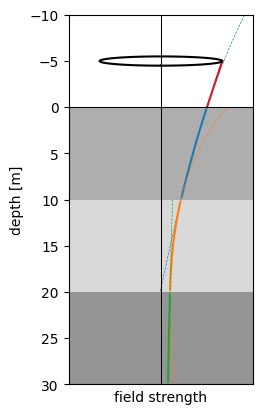

In [2]:
rho = [20, 8, 40]
sigma = [1./x for x in rho]
sgm_air = 1e-2
tx_height = 5.
A = np.array([
    [1., 0., 0., 0., 0., 0., 0., 0.],
    [np.exp(-sgm_air*tx_height), np.exp(sgm_air*tx_height), -1., -1., 0., 0., 0., 0.],
    [-sgm_air*np.exp(-sgm_air*tx_height), sgm_air*np.exp(sgm_air*tx_height), sigma[0], -sigma[0], 0., 0., 0., 0.],
    [0., 0., np.exp(-sigma[0]*10), np.exp(sigma[0]*10), -1., -1., 0., 0.],
    [0., 0., -sigma[0]*np.exp(-sigma[0]*10), sigma[0]*np.exp(sigma[0]*10), sigma[1], -sigma[1], 0., 0.],
    [0., 0., 0., 0., np.exp(-sigma[1]*10), np.exp(sigma[1]*10), -1., -1.],
    [0., 0., 0., 0., -sigma[1]*np.exp(-sigma[1]*10), sigma[1]*np.exp(sigma[1]*10), sigma[2], -sigma[2]],
    [0., 0., 0., 0., 0., 0., 0., 1.]
])
b = np.array([1, 0, 0, 0, 0, 0, 0., 0.])
x = solve(A, b)
from plog import Log
thickness = np.array([10, 20])
lg = Log.standard(np.log10(np.array([0.5, 0.1, 1])), thickness, 'conductivity')
lg.depth_bot[-1] = 30
A_up = x[1::2]
A_dn = x[::2]

z = np.linspace(-10, 20, 100)
z_air = np.linspace(0, tx_height, 100)

ax,pcm = lg.plot(cmap='Greys', vmin=-2, vmax=2)


for i in [-1, 0, 1, 2]:
    if i == -1:
        sgm = sgm_air
        y1 = np.exp(-sgm*z_air)*A_dn[0]
        y2 = np.exp(sgm*z_air)*A_up[0]
        ax.plot(y1 + y2, z_air+i*tx_height, f'r')
        tx_amp = A_dn[0]+A_up[0]
        # ax.plot(y2, z_air+i*10, f'C5--')
    else:
        sgm = sigma[i]
        y = A_up[i+1] * np.exp(sgm * z) + A_dn[i+1] * np.exp(-sgm * z)
        ax.plot(y, z+i*10, f'C{i}--', linewidth=0.5)
        in_layer = (z>0) & (z<10)
        ax.plot(y[in_layer], z[in_layer]+i*10, f'C{i}')

theta = np.linspace(0, 2.*np.pi, 100)
y = 0.5*np.cos(theta)-tx_height
x = np.sin(theta)*tx_amp
ax.plot(x, y, 'k-')
ax.set_aspect(0.05)
ax.set_ylim(30, -10)
ax.set_xlim(-0.5, 0.5)
ax.set_xticks([]);
ax.plot([0,0], [-10, 30], 'k-', linewidth=0.75)
ax.plot([-0.5,0.5], [0,0], 'k-', linewidth=0.75)

ax.set_xlabel('field strength')
ax.set_ylabel('depth [m]')

In [3]:
A_up

array([-0.667944  , -0.04082236,  0.00562969,  0.        ])